# BMW Global Sales Analysis (2018–2025)

As a long-time automotive enthusiast with a particular interest in the BMW brand, I wanted this project to go beyond a standard data exercise. The goal was to combine my passion for the industry with data analysis, while enriching the findings with external context drawn from culture, geography, and macroeconomics where relevant.

The dataset used in this analysis is publicly available on Kaggle: [BMW Global Sales Analysis 2018–2025](https://www.kaggle.com/datasets/mohamedamiralkrdawy/bmw-global-sales-analysis-20182025). It covers the **BMW Group** across four major regions (China, Europe, Usa, Restofworld) from **2018 to 2025**, and includes not only BMW-branded vehicles but also the **MINI** nameplate, reflecting the group's full commercial portfolio.

The objective of this analysis is twofold: first, to **identify the key trends** shaping the BMW Group's global performance over this period, across sales volumes, model mix, powertrain transition, pricing, and seasonality; and second, to **translate these findings into actionable recommendations** that could inform strategic decisions around product, market, and commercial priorities.

## Contents

- **1. Global view**: overall BMW sales trend from 2018 to 2025, then broken down by region
- **2. Dimensions view**: sales trends and portfolio mix by region and by model
- **3. EV vs Thermal**: BMW's powertrain transition, globally and by region
- **4. Premium share**: regional premium market positioning
- **5. Revenue & Pricing**: revenue and price analysis by model and region
- **6. Macroeconomic factors**: GDP growth and fuel price index against sales and EV adoption
- **7. Seasonality**: monthly sales patterns, globally and by region
- **8. Conclusion**: summary of findings

In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv("bmw_data_cleaned.csv")
df.head(10)

,Year,Month,Region,Model,Units_Sold,Avg_Price_EUR,Revenue_EUR,BEV_Share,Premium_Share,GDP_Growth,Fuel_Price_Index
0,2021,12,Europe,X3,9715,58256.0,565957040.0,0.078,19.94,2.80,1.20
1,2024,4,Europe,3 Series,12042,47648.0,573777216.0,0.151,16.13,3.25,1.23
2,2022,9,Usa,MINI,8458,40122.0,339351876.0,0.119,18.12,3.76,1.22
3,2019,4,Restofworld,MINI,6710,43668.0,293012280.0,0.045,6.62,3.44,1.08
4,2022,1,Restofworld,iX,6091,75460.0,459626860.0,0.126,5.55,2.50,1.20
5,2020,1,Usa,iX,11133,73946.0,823240818.0,0.076,14.91,2.96,1.06
6,2018,12,Europe,X3,12695,56159.0,712938505.0,0.012,20.78,2.50,0.99
7,2022,11,China,3 Series,3861,47092.0,181822212.0,0.127,19.33,1.18,1.18
8,2025,6,China,i4,9116,65168.0,594071488.0,0.196,16.87,2.17,1.31
9,2019,1,Restofworld,3 Series,9032,49731.0,449170392.0,0.069,6.50,3.26,1.06


In [3]:
# Palette definition for global coherence
country_palette = {'China':'#C44E52','Restofworld':'#DD8452','Usa':'#4C72B0','Europe':'#55A868'}

## 1. Global view

This section establishes the overall BMW sales trajectory between 2018 and 2025, before breaking it down by region.

### 1.a Has BMW sales increased over the period 2018-2025?

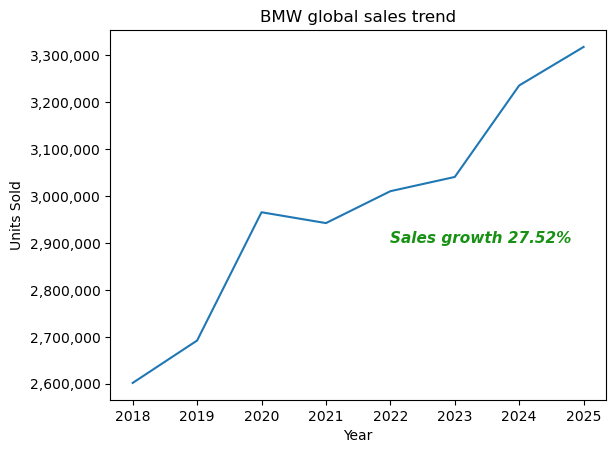

In [4]:
sales_year = df.groupby('Year')['Units_Sold'].sum()
sales_2018 = sales_year[2018]
sales_2025 = sales_year[2025]
sales_growth = ((sales_2025-sales_2018)/sales_2018) * 100

ax = sns.lineplot(data=sales_year.reset_index(), x='Year', y='Units_Sold')
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.StrMethodFormatter('{x:,.0f}'))
ax.set_title('BMW global sales trend')
ax.text(x=2022, y=2900000, s=f'Sales growth {sales_growth:,.2f}%', color='#199115', fontstyle='italic', fontweight='bold', fontsize=11)
ax.set_ylabel('Units Sold');

BMW global sales increased by **27.52%** over the 2018-2025 period, from 2,601,764 to 3,317,888, confirming a clear upward trend despite short-term fluctuations.

### 1.b What is the total sales distribution across regions over the 2018-2025 period?

,Sales count,Sales Percentage
China,6076952,25.526308
Usa,5931187,24.914021
Restofworld,5916794,24.853563
Europe,5881690,24.706108
Subtotal,23806623,100.000000


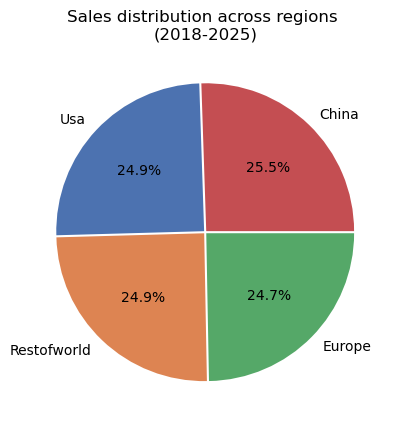

In [5]:
sales_region = df.groupby('Region')['Units_Sold'].sum()
sales_percent = sales_region / sales_region.sum() * 100
region_summary = pd.DataFrame(data={'Sales count': sales_region, 'Sales Percentage': sales_percent})
subtotal = pd.DataFrame({'Sales count': [sales_region.sum()], 'Sales Percentage': [100]}, index=['Subtotal'])
region_summary = region_summary.sort_values('Sales count', ascending=False)
region_summary = pd.concat([region_summary, subtotal])

# Subtotal excluded from pie chart
ax = plt.pie(x=region_summary.drop('Subtotal')['Sales Percentage'], labels=region_summary.drop('Subtotal').index, autopct='%.1f%%', colors=['#C44E52','#4C72B0', '#DD8452', '#55A868'], explode=[0.01, 0.01, 0.01, 0.01])
plt.title('Sales distribution across regions \n(2018-2025)');
region_summary

Over the **2018-2025** period, the **Chinese** market generated the highest sales count with **6,076,952** units sold, while the **European** market had the lowest count with **5,881,690** units. Sales are remarkably balanced across all four regions, with less than **3.4%** separating them.

## 2. Dimensions view

This section moves from the global view to BMW's two core dimensions, region and model, examining how sales trends, portfolio mix, and growth rates differ across markets and vehicle lines.

### 2.a Sales trend by region

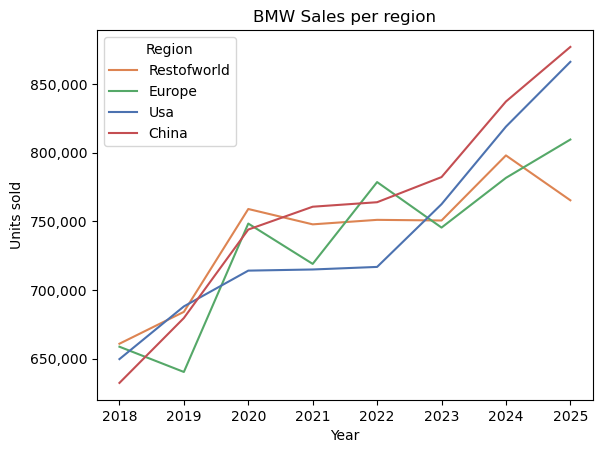

Total sales growth 2018-2020: 13.98%
Total sales growth 2020-2023: 2.54%
Total sales growth 2023-2025: 9.11%


In [6]:
sales_year_region = df.groupby(['Year', 'Region'])['Units_Sold'].sum().reset_index().sort_values(['Year', 'Units_Sold'], ascending=[True, False])

ax = sns.lineplot(data=sales_year_region, x='Year', y='Units_Sold', hue='Region', palette=country_palette)
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.StrMethodFormatter('{x:,.0f}'))
ax.set_title('BMW Sales per region')
ax.set_ylabel('Units sold')
plt.show()

sales_2020 = sales_year[2020]
sales_2023 = sales_year[2023]
sales_growth_2018_2020 = ((sales_2020-sales_2018)/sales_2018) * 100
sales_growth_2020_2023 = ((sales_2023-sales_2020)/sales_2020) * 100
sales_growth_2023_2025 = ((sales_2025-sales_2023)/sales_2023) * 100
print(f'Total sales growth 2018-2020: {sales_growth_2018_2020:.2f}%')
print(f'Total sales growth 2020-2023: {sales_growth_2020_2023:.2f}%')
print(f'Total sales growth 2023-2025: {sales_growth_2023_2025:.2f}%')

Three distinct phases can be visually identified over the period:

* **Phase 1 (2018–2020):** Strong sales growth across all regions, with the **Usa** market as the only exception showing more modest performance
* **Phase 2 (2020–2023):** Growth slows significantly across all regions, with **China** and the **Usa** as the only markets maintaining positive momentum
* **Phase 3 (2023–2025):** A broad recovery emerges, led by **China**, the **Usa**, and **Europe**, while **Restofworld** remains the outlier with limited rebound

The following analysis quantifies these observations.

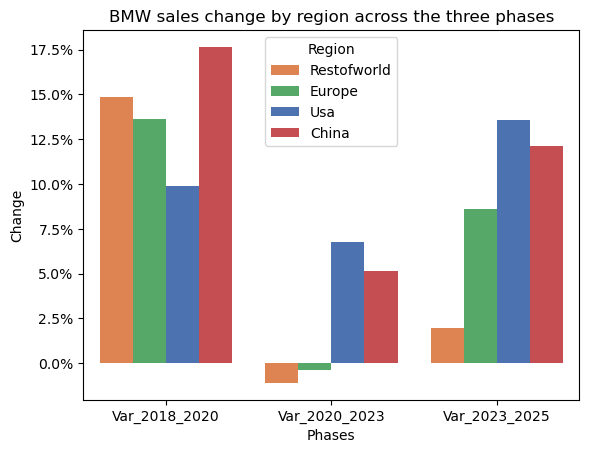

In [7]:
# Function for getting region sales on key years 2018, 2020, 2023, 2025
def sales_region_phases(region):
    x_2018 = sales_year_region[(sales_year_region['Year']==2018) & (sales_year_region['Region']==region)]
    x_2020 = sales_year_region[(sales_year_region['Year']==2020) & (sales_year_region['Region']==region)]
    x_2023 = sales_year_region[(sales_year_region['Year']==2023) & (sales_year_region['Region']==region)]
    x_2025 = sales_year_region[(sales_year_region['Year']==2025) & (sales_year_region['Region']==region)]
    return x_2018['Units_Sold'].values[0], x_2020['Units_Sold'].values[0],x_2023['Units_Sold'].values[0], x_2025['Units_Sold'].values[0]

region_figures = []

for region in sales_year_region['Region'].unique():
    current_region_sales = sales_region_phases(region)
    region_figures.append((region,) + current_region_sales)


# Putting tuples into a dataframe
phases = pd.DataFrame(data=region_figures,index=None,columns=['Region','Sales_2018','Sales_2020','Sales_2023','Sales_2025'])

# Calculating regions' sales change over the 3 phases
phases['Var_2018_2020'] = ((phases['Sales_2020'] - phases['Sales_2018']) / phases['Sales_2018']) * 100
phases['Var_2020_2023'] = ((phases['Sales_2023'] - phases['Sales_2020']) / phases['Sales_2020']) * 100
phases['Var_2023_2025'] = ((phases['Sales_2025'] - phases['Sales_2023']) / phases['Sales_2023']) * 100
phases[['Region', 'Var_2018_2020', 'Var_2020_2023', 'Var_2023_2025']]

# Switching to long format for visualisation
phases_long = pd.melt(phases, id_vars='Region',value_vars=['Var_2018_2020','Var_2020_2023','Var_2023_2025'], var_name='Phases',value_name='Change')

ax = sns.barplot(data=phases_long, x='Phases', y='Change', hue='Region', palette=country_palette, saturation=1)
ax.set_title("BMW sales change by region across the three phases")
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter())

Quantifying the three phases confirms and sharpens the visual observation.

During **Phase 1 (2018–2020)**, the **Chinese** market led with exceptional growth of **+17.65%**, while the **Usa** market posted the weakest performance at **+9.9%**, roughly half that of China.

During **Phase 2 (2020–2023)**, growth slowed across all regions. **Restofworld** and **Europe** turned negative at **-1.1%** and **-0.4%** respectively, while **China** and the **Usa** maintained positive but significantly reduced momentum at **+5.13%** and **+6.77%**.

During **Phase 3 (2023–2025)**, a strong recovery materialized. The **Usa** led the rebound at **+13.58%**, followed by **China** at **+12.11%** and **Europe** at **+8.6%**. **Restofworld** returned to a modest positive at **+1.95%**, but remains well below its Phase 1 peak.

These results reveal distinct market profiles. The **Usa** market is the most consistent performer, averaging around **+9% growth per phase** with no negative readings. The **Chinese** market delivers the highest peaks but is more exposed to sharp slowdowns when economic conditions deteriorate: its growth rate fell from **+17%** to **+5%** between phases 1 and 2. **Europe** and **Restofworld** share a similar vulnerability to downturns, with **Restofworld** showing more dramatic swings and a weaker recovery capacity.

*Hypothesis: the Phase 2 slowdown likely reflects the combined impact of COVID-19 disruptions and the global semiconductor shortage, both of which severely constrained automotive production capacity worldwide.*

### 2.b BMW model performance: sales volume and portfolio share (2018–2025)

In [8]:
# Units sold per model and per year, sorted by year then by best-selling model
sales_year_model = df.groupby(['Year', 'Model'])['Units_Sold'].sum().reset_index().sort_values(['Year', 'Units_Sold'], ascending=[True, False])

# Total sales & portfolio share
sales_model = sales_year_model.groupby('Model')['Units_Sold'].sum().sort_values(ascending=False)
portfolio_share_model = (sales_model / sales_model.sum())*100
display(pd.DataFrame({'Total_Sales':sales_model, 'Portfolio_Share':portfolio_share_model.round(2)}))

# Highest vs lowest sales difference
gap_i4_mini = sales_model['i4'] - sales_model['MINI']
gap_pct = (gap_i4_mini / sales_model['i4']) * 100
print(f"Gap highest (i4) vs lowest (MINI): {gap_i4_mini:,.0f} units ({gap_pct:.1f}%)")

,Total_Sales,Portfolio_Share
Model,,
i4,3035495,12.75
iX,3017938,12.68
X7,3010926,12.65
X5,2978586,12.51
5 Series,2969842,12.47
X3,2950415,12.39
3 Series,2928443,12.30
MINI,2914978,12.24


Gap highest (i4) vs lowest (MINI): 120,517 units (4.0%)


By looking at overall total sales, we notice that sales figures are very similar amongst all vehicles. The difference between the top (**i4**) and the bottom (**MINI**) seller over the period is only **120,517 units**, representing only a **3.98%** sales difference and **0.51%** in portfolio share.

### 2.c BMW model sales per year

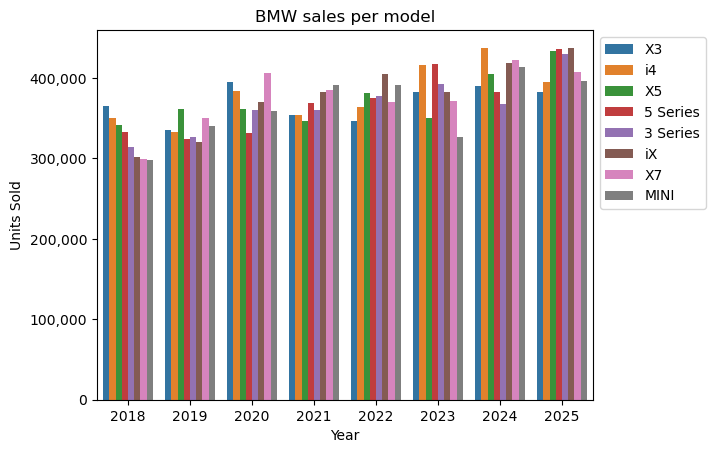

In [9]:
ax = sns.barplot(data=sales_year_model, x='Year', y='Units_Sold', hue='Model')
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.StrMethodFormatter('{x:,.0f}'))
ax.set_ylabel('Units Sold')
ax.legend(loc='upper left', bbox_to_anchor=(1, 1));
ax.set_title('BMW sales per model');

The barplot reveals a significant shift in **BMW's model mix** between 2018 and 2025. The **X3**, which led sales in 2018, dropped to last place by 2025, while the **iX** and **3 Series** moved in the opposite direction: from the bottom of the ranking to the top. This suggests a notable change in consumer preferences over the period.

### 2.d Portfolio share evolution per model

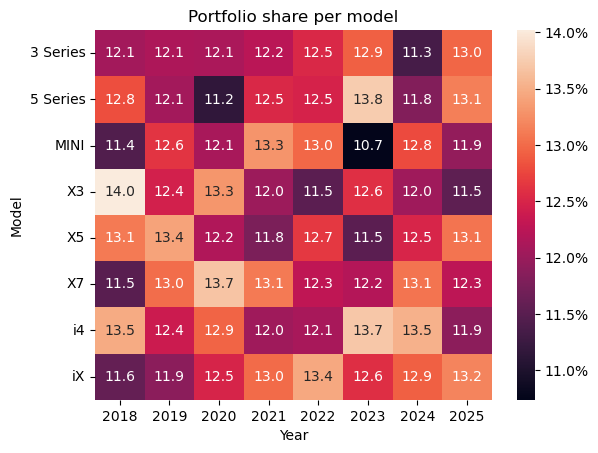

In [10]:
year_model_portfolio_share = pd.merge(sales_year_model, sales_year, on='Year', suffixes=('_sales','_current_year')).assign(
    Portfolio_share= lambda df: df['Units_Sold_sales'] / df['Units_Sold_current_year'] * 100).round(2)[[
        'Year','Model','Portfolio_share']]

year_model_portfolio_share_wide = year_model_portfolio_share.pivot(index='Model', columns='Year', values='Portfolio_share')
ax = sns.heatmap(data=year_model_portfolio_share_wide, annot=True, fmt='.1f')
ax.set_title('Portfolio share per model')
ax.collections[0].colorbar.ax.yaxis.set_major_formatter((plt.matplotlib.ticker.PercentFormatter(decimals=1)))

The portfolio share values are remarkably stable across all models over the period, with the vast majority clustered between **11%** and **14%**, a spread of only **3 percentage points**. Extreme values are rare, which suggests BMW actively manages its catalogue balance rather than letting any single model dominate.

Looking within individual models, some volatility emerges. The **X3** started as the highest-share model in 2018 (**14.0%**) but gradually declined toward the average by 2025 (**11.5%**), while the **MINI** posted the lowest single value of the entire dataset in 2023 (**10.7%**) before partially recovering. The **3 Series**, by contrast, remained consistently close to the average throughout the period, ending slightly above it at **13.0%** in 2025.

Overall, this heatmap confirms that no model structurally dominates BMW's portfolio. The brand maintains a deliberately diversified lineup where share shifts are gradual rather than abrupt.

### 2.e Model growth (2018–2025)

,Model,Var_2018_2025
0,X3,4.94
1,i4,12.66
2,X5,27.20
3,5 Series,30.79
7,MINI,33.21
6,X7,36.06
4,3 Series,36.92
5,iX,45.01


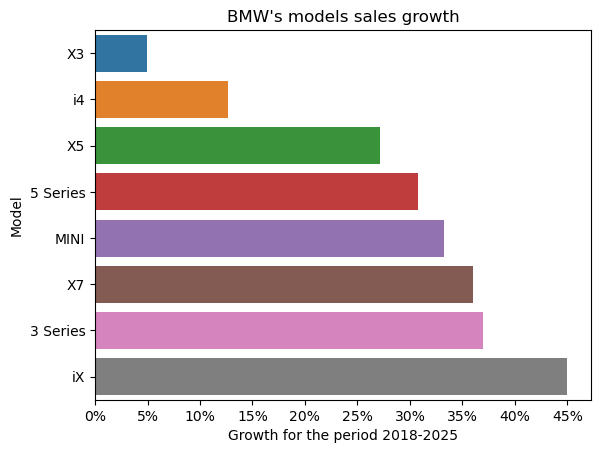

In [11]:
def sales_model_variation(model):
    x_2018 = sales_year_model[(sales_year_model['Year'] ==2018) & (sales_year_model['Model']==model)]
    x_2025 = sales_year_model[(sales_year_model['Year'] ==2025) & (sales_year_model['Model']==model)]
    return x_2018['Units_Sold'].values[0], x_2025['Units_Sold'].values[0]

model_sales = []

for model in sales_year_model['Model'].unique():
    current_model_sales = sales_model_variation(model)
    model_sales.append((model,) + current_model_sales)

# Putting tuples into a dataframe
model_growth = pd.DataFrame(data=model_sales,columns=['Model','Sales_2018','Sales_2025'])
model_growth['Var_2018_2025'] = ((model_growth['Sales_2025']-model_growth['Sales_2018']) / model_growth['Sales_2018']) * 100
model_growth = model_growth[['Model', 'Var_2018_2025']].sort_values('Var_2018_2025',ascending=True).round(2)

ax = sns.barplot(data=model_growth, x='Var_2018_2025',y='Model', hue='Model')
ax.set_xlabel('Growth for the period 2018-2025')
ax.xaxis.set_major_locator(plt.matplotlib.ticker.MultipleLocator(5))
ax.set_title("BMW's models sales growth")
ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(decimals=0))
model_growth

The **iX** leads all models with the strongest growth over the period at **+45%**, while the **X3** trails significantly behind with a modest **+3%** increase.

With the available data, no definitive conclusion can be drawn. However, a few hypotheses can be made:

* A shift in consumer preference toward electric vehicles may explain the **iX**'s growth, as it is BMW's flagship EV. That said, the **i4**, also electric, ranks among the lowest performers, which weakens this hypothesis on its own.
* The **X3** may have suffered from brand or product perception issues: despite starting as the highest-selling model, its sales barely grew over the period.
* The **X3** belongs to an older generation. Car models often retain the same name across generations, meaning a lack of meaningful renewal could have limited its appeal.

### 2.f Which models lead sales in each region?
#### Total model sales from 2018 to 2025

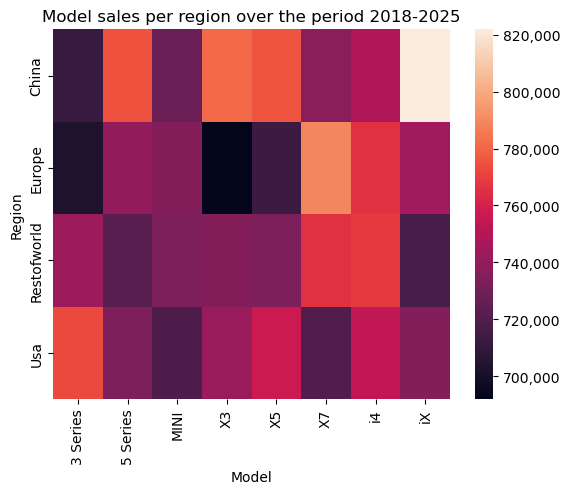

In [12]:
sales_region_model = df.groupby(['Region', 'Model'])['Units_Sold'].sum().reset_index()
sales_region_model_wide = sales_region_model.pivot(index='Region', columns='Model', values='Units_Sold')

ax = sns.heatmap(data=sales_region_model_wide)
ax.set_title('Model sales per region over the period 2018-2025')
ax.collections[0].colorbar.ax.yaxis.set_major_formatter('{x:,.0f}')

**Clear trends can be identified across markets:**

* In **China**, the **iX** leads sales, consistent with China's strong push toward EV adoption, followed by the **X3** and **X5**, two traditional SUVs. This suggests that SUVs dominate the Chinese market regardless of powertrain.
* In **Europe**, the **X7** leads, followed by two EVs: the **i4** and **iX**, suggesting a market with a strong appetite for both large SUVs and electric vehicles.
* In **Restofworld**, the **i4** leads sales, but the rest of the top models are all thermal, suggesting that while EV interest exists, traditional powertrains still dominate this market.
* In the **Usa**, the **3 Series** leads, followed by the **X5** and the **i4**. The large vehicle segment faces intense competition from pickup trucks. The Ford F-150 has been the best-selling vehicle in the country for decades, which may explain why BMW's large SUV models perform less strongly here compared to other regions.

It is worth noting that the differences between models remain modest, with all models clustered within a **~120,000 unit range** over the period. This analysis nonetheless reveals that consumer preferences vary significantly by market. A manufacturer cannot apply a one-size-fits-all strategy globally: EV appetite is strong in **China** and **Europe**, while the **Usa** and **Restofworld** remain more anchored to traditional powertrains. Within these broad trends, further nuances emerge. **China** favours SUVs regardless of powertrain, while the **Usa** stands out as the only market where a sedan leads.

#### Model sales per year

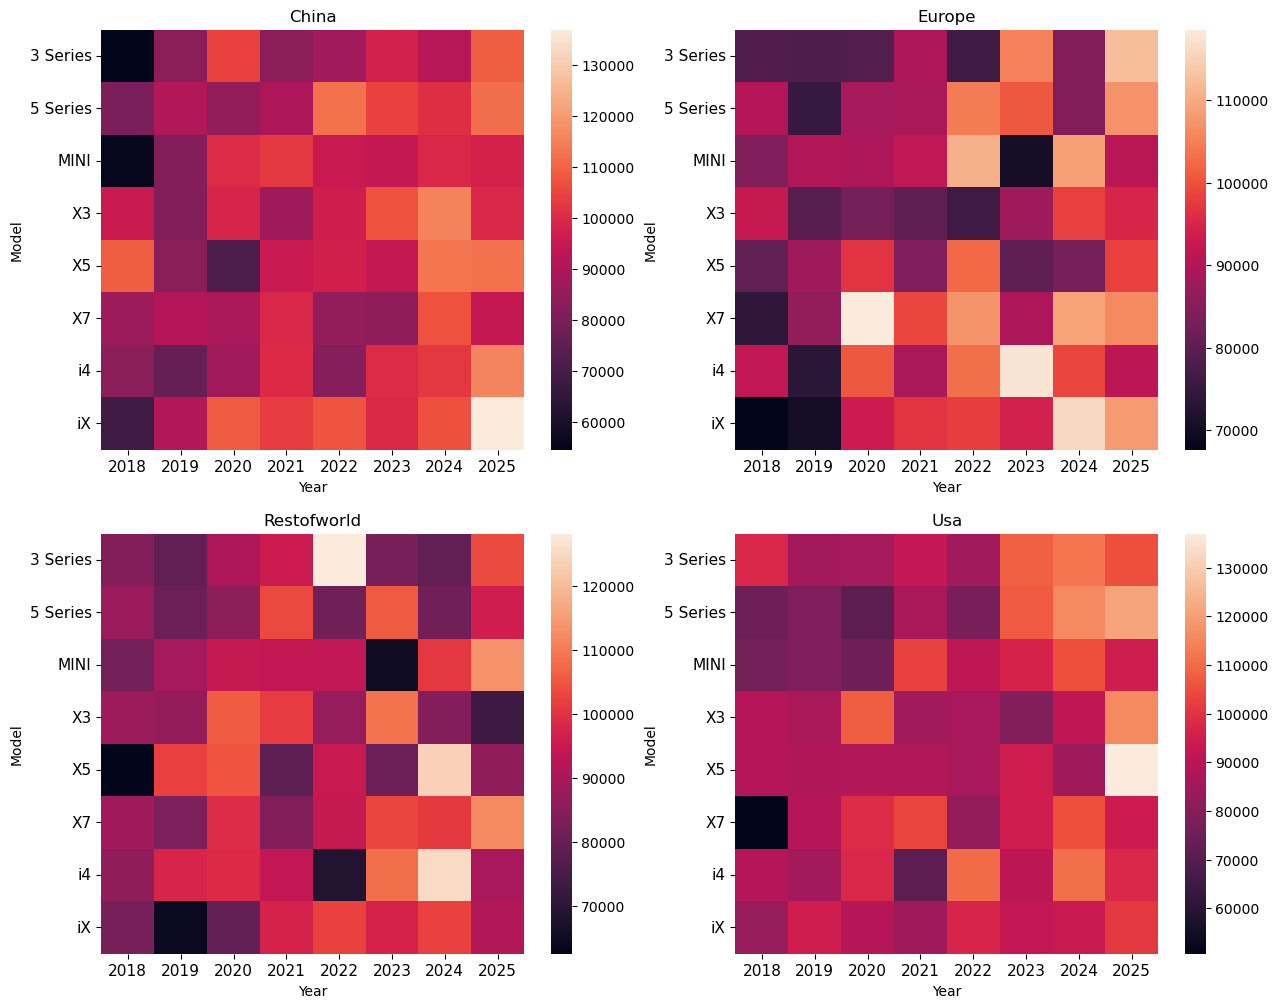

In [13]:
sales_region_model_year = df.groupby(['Region','Model','Year'])['Units_Sold'].sum().reset_index()

fig, ax = plt.subplots(2, 2, figsize=(15, 12))
ax = ax.flatten()
i = 0

for region in sales_region_model_year['Region'].unique():
    sns.heatmap(data=sales_region_model_year[sales_region_model_year['Region']==region].pivot(index='Model',columns='Year',values='Units_Sold'), ax=ax[i])
    ax[i].set_title(region)
    ax[i].tick_params(labelsize=11)
    i += 1

Based on the four heatmaps, distinct model preferences emerge across regions over the 2018–2025 period.

In **China**, the **3 Series** was the clear leader in 2018 before experiencing a sharp decline, while the **iX** progressively gained traction, consistent with China's strong push toward electrification observed in section 3.

In **Europe**, the **X7** posted a notable peak around 2020 before stabilizing, while the **iX** started from a very low base in 2018 and grew steadily. Europe appears to show the most balanced model mix over the period.

In **Restofworld**, the **X5** dominated in 2018 and the **MINI** recorded a strong spike in 2022, suggesting a more volatile and less predictable market compared to other regions.

In **Usa**, the **X7** started at a very low level in 2018 but showed a clear upward trend over the period, becoming one of the stronger performers by 2025. This is somewhat surprising given the competitive pressure from pickup trucks mentioned in section 2.

Overall, while each region shows its own distinct model preferences, a common trend emerges across all four markets: **EV models (iX, i4)** started from a low base in 2018 and gained visibility over the period, though at different speeds depending on the region.

## 3. EV vs Thermal

This section examines BMW's powertrain transition, comparing electric (`iX`, `i4`) and thermal vehicle sales globally and by region to assess how far and how evenly the shift toward EVs has progressed.

### 3.a Global EV vs Thermal volume

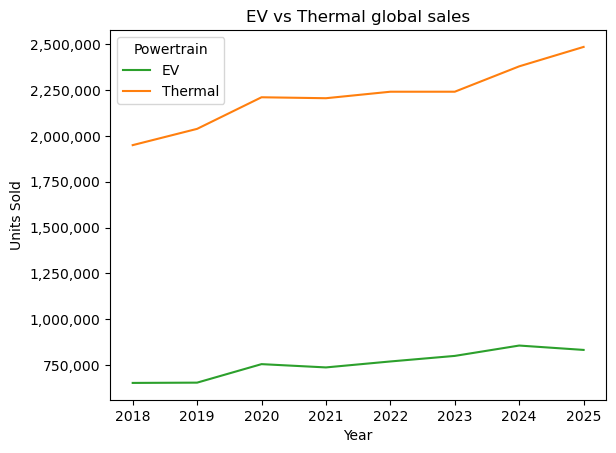

In [14]:
# Listing EVs
ev_models = ['iX', 'i4']

ev_sales_year = sales_year_model[sales_year_model['Model'].isin(ev_models)].groupby('Year')['Units_Sold'].sum().reset_index()

thermal_sales_year = sales_year_model[~sales_year_model['Model'].isin(ev_models)].groupby('Year')['Units_Sold'].sum().reset_index()

sales_year_powertrain = pd.concat([ev_sales_year.assign(Powertrain='EV'),thermal_sales_year.assign(Powertrain='Thermal')])
ax = sns.lineplot(data=sales_year_powertrain, x='Year',y='Units_Sold',hue='Powertrain', palette={'EV':'#2CA02C','Thermal':'#FF7F0E'})
ax.set_title('EV vs Thermal global sales')
ax.set_ylabel('Units Sold')
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.StrMethodFormatter('{x:,.0f}'))

The chart clearly shows that **thermal vehicle sales** significantly outpace **EV sales** throughout the entire period, with the gap remaining stable rather than narrowing. In 2025, thermal sales reached approximately **2.5 million units** against **800,000** for EVs, a ratio of roughly **3 to 1**.

From 2023 onwards, thermal sales accelerated sharply while EV volumes saw only a modest increase, before plateauing in 2025. This divergence suggests that despite BMW's EV push, thermal vehicles continue to drive the bulk of the group's volume growth.

### 3.b Global EV share

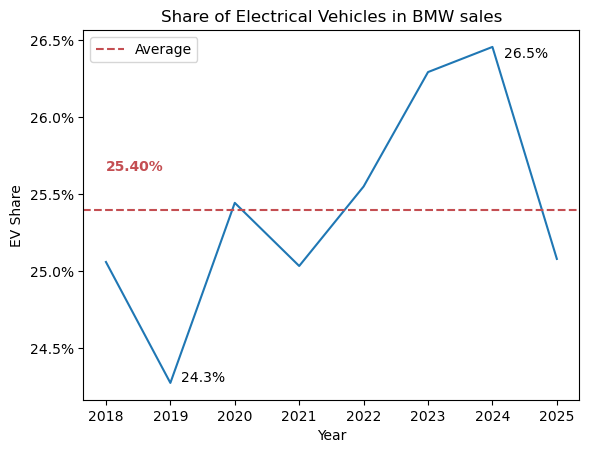

In [15]:
ev_share_year = ev_sales_year.set_index('Year')['Units_Sold'] / sales_year
ev_share_year = pd.DataFrame(data=ev_share_year, index=None)

# Putting values in percent for better readability
ev_share_year = ev_share_year.rename(columns={'Units_Sold': 'EV_Share'})
ev_share_year['EV_Share'] = ev_share_year['EV_Share'] * 100

max_year = ev_share_year['EV_Share'].idxmax()
min_year = ev_share_year['EV_Share'].idxmin()

ax = sns.lineplot(data=ev_share_year, x='Year', y='EV_Share')
ax.set_title('Share of Electrical Vehicles in BMW sales')
ax.set_ylabel('EV Share')
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(decimals=1))
ax.axhline(y=ev_share_year['EV_Share'].mean(), linestyle='dashed', color='#C44E52', label='Average')
ax.text(x=2018, y=ev_share_year['EV_Share'].mean() + 0.25, s=f'{ev_share_year['EV_Share'].mean():.2f}%', color='#C44E52', fontsize=10, fontweight='bold')
ax.annotate(f"{ev_share_year.loc[max_year, 'EV_Share']:.1f}%", xy=(max_year, ev_share_year.loc[max_year, 'EV_Share']), xytext=(8, -8), textcoords='offset points')
ax.annotate(f"{ev_share_year.loc[min_year,'EV_Share']:.1f}%", xy=(min_year, ev_share_year.loc[min_year, 'EV_Share']), xytext=(8, 1), textcoords='offset points')
ax.legend();

The chart clearly shows an upward trend with notable fluctuations up to 2024, where the peak is reached at **26.5%** of sales. However, in 2025, the EV share drops back to a level similar to 2018: **25.08%** vs **25.06%** at the start of the period. With a minimum of **24.3%**, the average sits at **25.4%**, reflecting a balanced distribution. Despite this solid position, overall progression over the period remains weak, with only **2.2 percentage points** of growth. In 2025, the EV share takes a **1.4-point dip** and falls below the average. This drop could be explained by a multitude of factors not available in this dataset, but several hypotheses can be made:

* the market is reaching saturation, with many brands offering all or part of their lineup as electric
* the rise of Chinese competition attracting consumers away from premium European brands
* an ageing lineup that fails to appeal to consumers
* the abandonment of the goal to sell only **100% electric vehicles** in Europe by 2035, which may have shifted consumer sentiment
* an increase in the prices of vehicles offered by the group

### 3.c EV sales per region

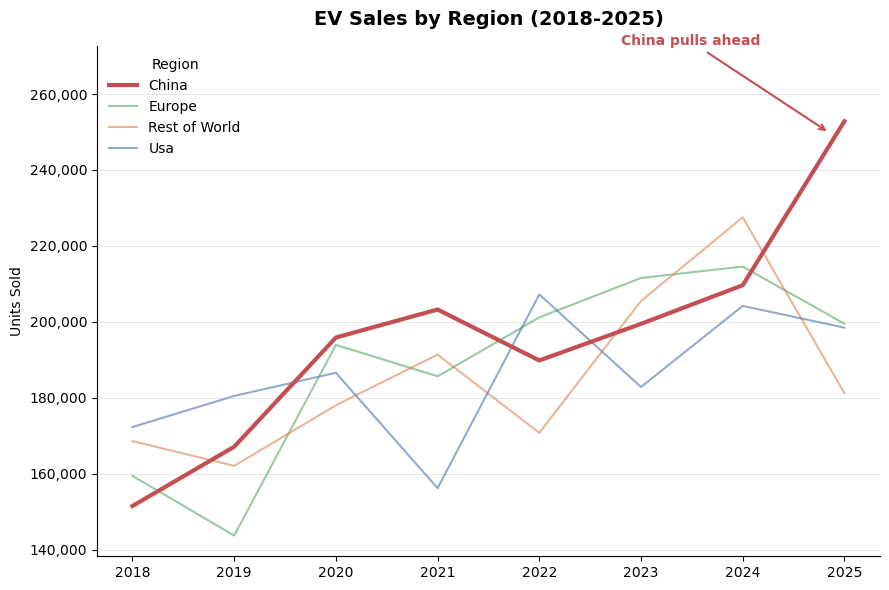

In [16]:
ev_sales_region_year = sales_region_model_year[sales_region_model_year['Model'].isin(ev_models)].groupby(['Region','Year'])['Units_Sold'].sum().reset_index()

fig, ax = plt.subplots(figsize=(9, 6))

for region in ev_sales_region_year['Region'].unique():
    data = ev_sales_region_year[ev_sales_region_year['Region'] == region]
    is_china = region == 'China'
    ax.plot(
        data['Year'], data['Units_Sold'],
        color=country_palette[region],
        linewidth=3 if is_china else 1.5,
        alpha=1.0 if is_china else 0.6,
        label='China' if is_china else region.replace('Restofworld', 'Rest of World'),
        zorder=3 if is_china else 2
    )

ax.yaxis.set_major_formatter(plt.matplotlib.ticker.StrMethodFormatter('{x:,.0f}'))
ax.set_ylabel('Units Sold')
ax.set_title('EV Sales by Region (2018-2025)', fontsize=14, fontweight='bold', pad=15)
ax.set_xlabel('')

# Clean up spines and add light gridlines
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.grid(axis='y', alpha=0.3, linewidth=0.7)
ax.set_axisbelow(True)

ax.legend(title='Region', frameon=False, loc='upper left')

# Add headroom above the highest point so the annotation text isn't cropped
ymin, ymax = ax.get_ylim()
ax.set_ylim(ymin, ymax + (ymax - ymin) * 0.12)

# Annotation in China's own color, arrow starting inside the plot area
china_2025 = ev_sales_region_year[(ev_sales_region_year['Region'] == 'China') & (ev_sales_region_year['Year'] == 2025)]
ax.annotate(
    'China pulls ahead',
    xy=(2024.85, china_2025['Units_Sold'].values[0] - 3000),
    xytext=(2022.8, china_2025['Units_Sold'].values[0] + 20000),
    fontsize=10, fontweight='bold', color=country_palette['China'],
    arrowprops=dict(arrowstyle='->', color=country_palette['China'], lw=1.5)
)

plt.tight_layout()
plt.savefig('images/ev_sales_per_region.png', dpi=200, bbox_inches='tight')

EV sales show a clear upward trend across all regions, largely dominated by the **Chinese market**, the only region to have recorded **positive year-on-year growth in 2025**. While **China** experienced only one year of decline over the period (2022), all other regions recorded at least **three years** of year-on-year decline.

### 3.d EV share per region

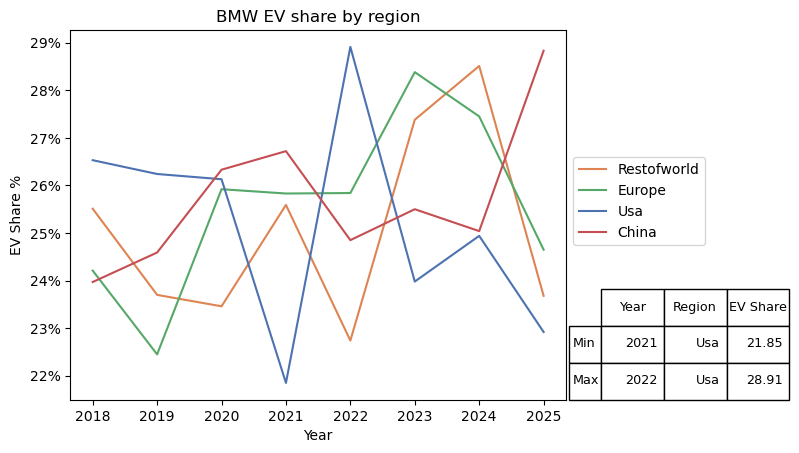

In [17]:
ev_sales_region_year_total = pd.merge(sales_year_region, ev_sales_region_year, on=['Region','Year'], suffixes=('_total','_ev'))
ev_sales_region_year_total['EV_Share'] = (ev_sales_region_year_total['Units_Sold_ev']/ev_sales_region_year_total['Units_Sold_total']*100).round(2)
ev_sales_region_year_total

min_ev = ev_sales_region_year_total['EV_Share'].idxmin()
max_ev = ev_sales_region_year_total['EV_Share'].idxmax()
min_max_ev = pd.concat([ev_sales_region_year_total.loc[[min_ev]], ev_sales_region_year_total.loc[[max_ev]]])
ax = sns.lineplot(data=ev_sales_region_year_total, x='Year',y='EV_Share',hue='Region', palette=country_palette)
ax.set_title('BMW EV share by region')
table_min_max_ev_share = plt.table(cellText=min_max_ev[['Year','Region','EV_Share']].values.tolist(),colLabels=['Year','Region','EV Share'],rowLabels=['Min','Max'],loc='bottom',bbox=[1.07,0,0.38,0.3])
table_min_max_ev_share.auto_set_font_size(False)
table_min_max_ev_share.set_fontsize(9.2)
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(decimals=0))
ax.legend(loc='lower left', bbox_to_anchor=(1, 0.4))
ax.set_ylabel('EV Share %');

The 2018–2025 period is marked by significant fluctuations and notable differences across regions:

* The **Usa** market displays the lowest EV share in 2021 but also the highest in 2022. However, a downward trend ultimately leaves it with the **lowest EV share** among all regions by the end of the period.
* **Restofworld** and **Europe** both experienced an upward trend until 2023, but returned to their starting levels by 2025.
* Finally, the **Chinese** market, despite fluctuations that kept its EV share stagnant until 2024, recorded a sharp surge in 2025, placing it in **first position** by the end of the period.

### 3.e Thermal sales per region

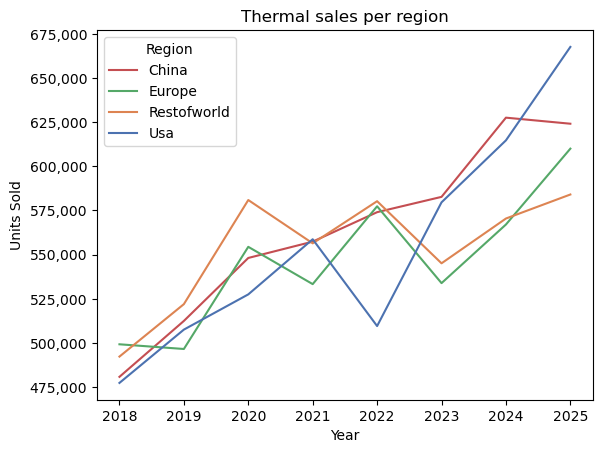

In [18]:
thermal_sales_region_year = sales_region_model_year[~sales_region_model_year['Model'].isin(ev_models)].groupby(['Region','Year'])['Units_Sold'].sum().reset_index()
ax = sns.lineplot(data=thermal_sales_region_year, x='Year', y='Units_Sold', hue='Region', palette=country_palette)
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.StrMethodFormatter('{x:,.0f}'))
ax.set_ylabel('Units Sold')
ax.set_title('Thermal sales per region');

Regarding thermal vehicles, we observe once again an upward trend, but this time more resilient, particularly in 2025, where **all regions show growth** except **China**, which experiences a slight inflection. Markets broadly followed similar trends, with increases between **2018 and 2020** and between **2023 and 2025**, and fluctuations in between. Finally, while the **US** market had the lowest thermal vehicle sales in 2018, it ended the 2018–2025 period as the **leader**, driven by a strong surge from 2023 onwards.

### 3.f EV vs Thermal growth

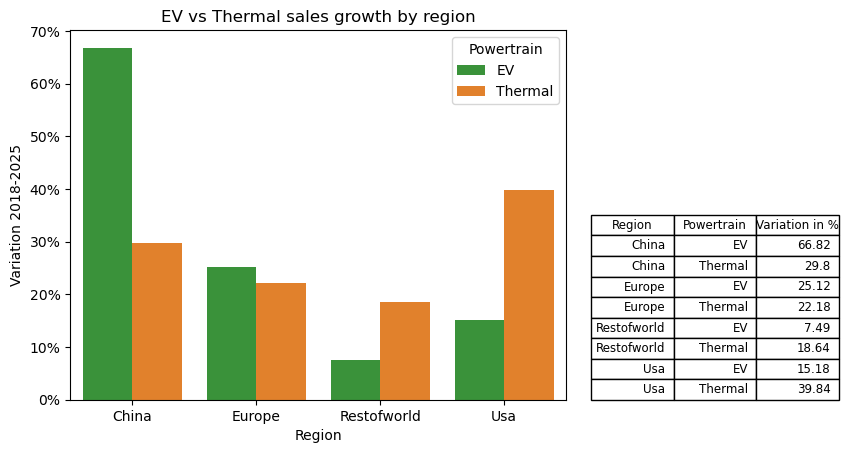

In [19]:
sales_region_powertrain_year = sales_region_model_year.assign(Powertrain=sales_region_model_year['Model'].apply(lambda x: 'EV' if x in ev_models else 'Thermal')).groupby(['Region','Powertrain','Year'])['Units_Sold'].sum().reset_index()


def growth_region_phases(region,powertrain):
    n_2018 = sales_region_powertrain_year[(sales_region_powertrain_year['Year']==2018) & (sales_region_powertrain_year['Region']==region) & (sales_region_powertrain_year['Powertrain']==powertrain)]
    n_2025 = sales_region_powertrain_year[(sales_region_powertrain_year['Year']==2025) & (sales_region_powertrain_year['Region']==region) & (sales_region_powertrain_year['Powertrain']==powertrain)]
    return n_2018['Units_Sold'].values[0], n_2025['Units_Sold'].values[0]

growth_region = []

for region in sales_region_powertrain_year['Region'].unique():
    for powertrain in sales_region_powertrain_year['Powertrain'].unique():
        current_region_growth = growth_region_phases(region,powertrain)
        growth_region.append((region,powertrain) + current_region_growth)

growth_phases = pd.DataFrame(data=growth_region,index=None,columns=['Region','Powertrain','Sales_2018','Sales_2025'])

growth_phases['Var_2018_2025'] = ((growth_phases['Sales_2025'] - growth_phases['Sales_2018']) / growth_phases['Sales_2018']) * 100
ax = sns.barplot(data=growth_phases, x='Region', y='Var_2018_2025', hue='Powertrain',palette={'EV':'#2CA02C','Thermal':'#FF7F0E'})
ax.set_title('EV vs Thermal sales growth by region')
ax.set_ylabel('Variation 2018-2025')
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter())
table_ev_vs_thermal = plt.table(cellText=growth_phases[['Region','Powertrain','Var_2018_2025']].assign(Var_2018_2025=growth_phases['Var_2018_2025'].round(2)).values.tolist(),colLabels=['Region','Powertrain','Variation in %'],loc='bottom',bbox=[1.05,0,0.5,0.5])
table_ev_vs_thermal.auto_set_font_size(False)
table_ev_vs_thermal.set_fontsize(8.5)

These four regions can be grouped into three distinct profiles:

* **China** stands out with EV growth nearly **double** that of thermal vehicles (**+66.8%** vs **+29.8%**), reflecting the country's aggressive push toward electrification
* **Usa and Restofworld** show the opposite pattern, with thermal vehicles significantly outgrowing EVs, particularly in the **Usa** (**+39.8%** vs **+15.2%**), suggesting these markets remain anchored to traditional powertrains
* **Europe** presents a more balanced picture, with EV and thermal growth tracking closely (**+25.1%** vs **+22.2%**), indicating a gradual but evenly-paced transition

## 4. Premium share

This section looks at `Premium_Share`, the proportion of premium vehicles in the broader market, to assess how BMW's positioning as a premium brand aligns with regional market conditions.

In [20]:
# Checking Premium_Share is a market-level variable (one value per Year/Month/Region, regardless of model)
df.groupby(['Year','Month','Region'])['Premium_Share'].nunique()

Year  Month  Region     
2018  1      China          1
             Europe         1
             Restofworld    1
             Usa            1
      2      China          1
                           ..
2025  11     Usa            1
      12     China          1
             Europe         1
             Restofworld    1
             Usa            1
Name: Premium_Share, Length: 384, dtype: int64

### 4.a Global premium share

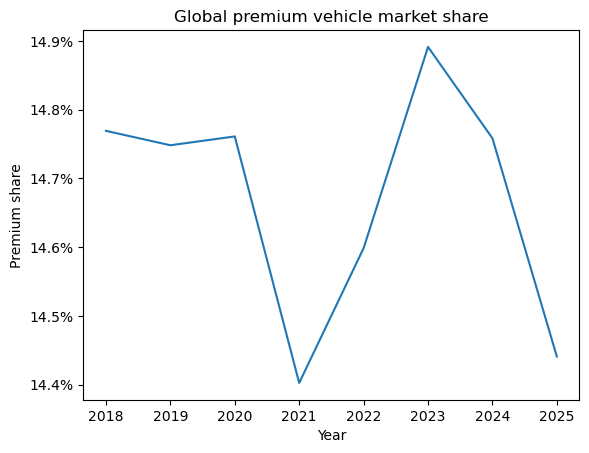

In [21]:
premium_share_global_per_year = df.groupby('Year')['Premium_Share'].mean()
ax=sns.lineplot(data=premium_share_global_per_year)
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(decimals=1))
ax.set_title('Global premium vehicle market share')
ax.set_ylabel('Premium share');

The global premium vehicle market share remained **remarkably stable** over the 2018–2025 period, fluctuating within a narrow **0.5 percentage point range** (**14.4%–14.9%**). Three distinct phases can be identified: a stable plateau around **14.75%** from 2018 to 2020, followed by a sharp single-year drop to a low of **14.4%** in 2021, likely linked to COVID-19's impact on consumer spending, then a recovery peaking at **14.9%** in 2023, before declining again to **14.45%** by 2025.

Despite these fluctuations, the overall stability of the premium segment suggests that demand for premium vehicles is structurally resilient and relatively insensitive to macroeconomic shocks. For BMW, this represents a **favorable and predictable market environment**.

### 4.b Premium share per region

Region,China,Europe,Restofworld,Usa
Year,,,,
2018,18.23,17.24,6.08,17.63
2019,17.50,17.88,6.18,17.22
2020,17.55,17.24,6.03,18.04
2021,16.63,17.90,6.02,17.21
2022,17.05,17.07,5.85,18.42
2023,18.19,17.52,6.06,17.64
2024,17.74,16.70,6.16,18.50
2025,17.73,17.17,5.53,17.34


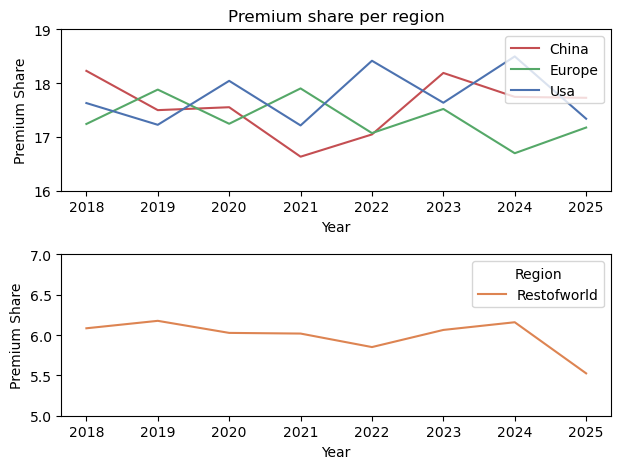

In [22]:
premium_share_year_region = df.groupby(['Year','Region'])['Premium_Share'].mean().reset_index()
fig, ax = plt.subplots(2,1)
sns.lineplot(data=premium_share_year_region[~(premium_share_year_region['Region']=='Restofworld')], x='Year',y='Premium_Share',hue='Region',palette=country_palette, ax=ax[0])
sns.lineplot(data=premium_share_year_region[premium_share_year_region['Region']=='Restofworld'],x='Year',y='Premium_Share',hue='Region',palette=country_palette, ax=ax[1])
ax[0].set_ylim(16,19)
ax[1].set_ylim(5,7)
ax[0].set_ylabel('Premium Share')
ax[1].set_ylabel('Premium Share')
ax[0].set_title('Premium share per region')
plt.tight_layout()
ax[0].legend(loc='upper right');

premium_share_year_region_wide = premium_share_year_region.pivot(index='Year', columns='Region',values='Premium_Share').round(2)
display(premium_share_year_region_wide)

A clear **structural gap** exists between **China**, **Europe** and the **Usa** on one side, averaging around **17.5%** premium share, and **Restofworld** on the other, hovering around **6%**. This near **3x difference** suggests fundamentally different market profiles.

Within the China, Europe and Usa group, markets were closely aligned between 2018 and 2020, with spreads between the highest and lowest values of only 0.99 points in 2018, 0.28 in 2019, and 0.44 in 2020. From 2021 onwards, divergences widened significantly: 1.27 points in 2021 and 1.37 in 2022, before partially converging again at 0.55 in 2023. The widest gap of the entire period was recorded in **2024 at 2.20 points**, driven by the **Usa** reaching its peak while **Europe** simultaneously hit its lowest value. By 2025, a broad downward trend reduced the spread to just **0.39 points**. The global minimum was recorded in 2021 by the **Chinese** market at **16.63%**, likely reflecting COVID-19's impact on premium consumer spending.

**Restofworld** followed a steady downward trend, declining from **6.08%** in 2018 to **5.53%** in 2025, with a brief peak of **6.18%** in 2019.

This structural gap between **Restofworld** and the other three regions is significant for BMW: operating in a low-premium market means consumers in that region are less predisposed to premium purchases, which may explain the weaker EV adoption and more conservative model preferences observed in earlier sections.

## 5. Revenue & Pricing

This section analyses BMW's financial performance using the `Revenue_EUR` and `Avg_Price_EUR` columns. The goal is to understand whether revenue differences across models and regions are driven by volume or by price.

### 5.a Global revenue

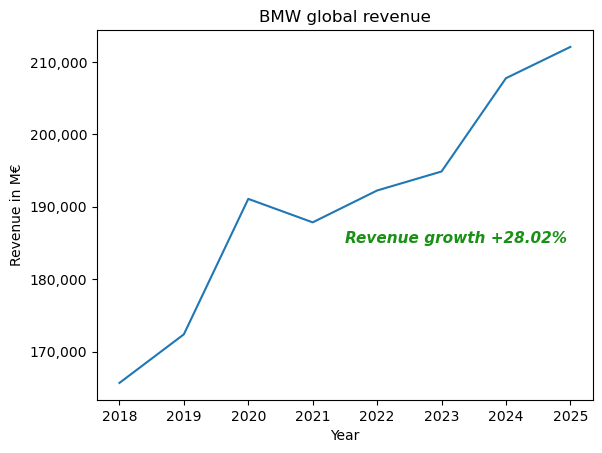

In [23]:
df['Revenue_M'] = df['Revenue_EUR'] / 1000000
revenue_M_year = df.groupby('Year')['Revenue_M'].sum()

revenue_growth = (revenue_M_year[2025] - revenue_M_year[2018]) / revenue_M_year[2018] * 100

ax = sns.lineplot(data=revenue_M_year)
ax.set_ylabel('Revenue in M€')
ax.set_title('BMW global revenue')
ax.text(x=2021.5, y=185000, s=f'Revenue growth +{revenue_growth:,.2f}%', color="#199115", fontstyle='italic', fontweight='bold', fontsize=11)
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.StrMethodFormatter('{x:,.0f}'));

A strong upward revenue trend is observed over the period, growing from 165,664 M€ in 2018 to 212,085 M€ in 2025, representing a +28.02% increase. Only one decline was recorded across the entire period: a modest -1.69% dip from 2020 to 2021, likely linked to the economic disruption caused by COVID-19.

Notably, revenue growth (+28.02%) slightly outpaces unit sales growth (+27.52% observed in section 1.a), suggesting that BMW's average selling price increased over the period, meaning the group sold more vehicles and at a higher average price, pointing to a gradual premiumisation of its lineup.

### 5.b Revenue per region

,Region,Revenue_2018,Revenue_2025,Var_2018_2025
0,China,41328.13,56066.71,35.66
1,Europe,41541.99,51986.69,25.14
2,Restofworld,42338.87,48900.39,15.50
3,Usa,40455.27,55131.49,36.28


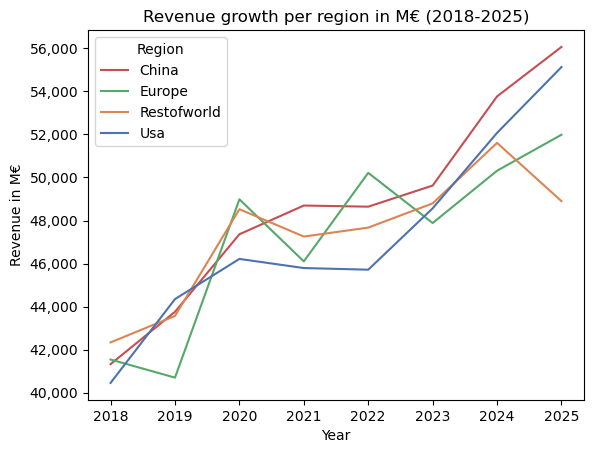

In [24]:
revenue_year_region = df.groupby(['Year','Region'])['Revenue_M'].sum().reset_index()
ax = sns.lineplot(data=revenue_year_region, x='Year',y='Revenue_M', hue='Region',palette=country_palette)
ax.set_ylabel('Revenue in M€')
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.StrMethodFormatter('{x:,.0f}'))
ax.set_title('Revenue growth per region in M€ (2018-2025)')
;

revenue_growth_region = []

for region in revenue_year_region['Region'].unique():
    revenue_region_2018 = revenue_year_region[(revenue_year_region['Year']==2018) & (revenue_year_region['Region']==region)]
    revenue_region_2025 = revenue_year_region[(revenue_year_region['Year']==2025) & (revenue_year_region['Region']==region)]
    revenue_growth_region.append((region,revenue_region_2018['Revenue_M'].values[0],revenue_region_2025['Revenue_M'].values[0]))

revenue_growth_region_2018_2025 = pd.DataFrame(data=revenue_growth_region,index=None,columns=['Region','Revenue_2018','Revenue_2025'])
revenue_growth_region_2018_2025['Var_2018_2025'] = ((revenue_growth_region_2018_2025['Revenue_2025'] - revenue_growth_region_2018_2025['Revenue_2018']) / revenue_growth_region_2018_2025['Revenue_2018']) * 100
revenue_growth_region_2018_2025.round(2)

All four regions contributed to the overall revenue growth of **+28.02%**, though with notable differences in performance. The **Usa** and **Chinese** markets posted remarkably similar growth rates at **+36.28%** and **+35.66%** respectively, both significantly above the global average. **Europe** grew at **+25.14%**, slightly below average, while **Restofworld** lagged behind at only **+15.50%**.

All regions shared the same broad cycle: growth from 2018 to 2020, stagnation or slight decline through 2023, followed by a recovery from 2023 onwards. One exception stands out: **Restofworld** appears to reverse course in 2025, recording a decline while all other regions continued to grow, suggesting this market may be losing momentum earlier than the rest.

### 5.c Revenue per model

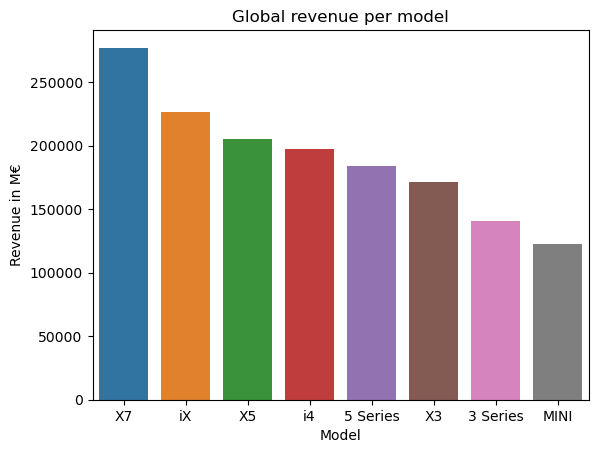

In [25]:
revenue_per_model = df.groupby('Model')['Revenue_M'].sum().reset_index().sort_values('Revenue_M', ascending=False)
ax = sns.barplot(data=revenue_per_model, x='Model', y='Revenue_M', hue='Model')
ax.set_ylabel('Revenue in M€')
ax.set_title('Global revenue per model');

**SUV and SAV models** dominate revenue generation, with the **X7**, **iX** and **X5** occupying the top three positions. The **X7** alone generated **277,124 M€** over the period, more than double the **MINI**'s **122,566 M€**. This gap is driven by price rather than volume: unit sales are remarkably balanced across all models, with less than **4%** separating the top and bottom sellers. It is therefore the higher average selling price of SUV and SAV models that explains their revenue leadership.

### 5.d Average price per model

In [26]:
model_avg_price = df.groupby('Model')['Avg_Price_EUR'].mean().sort_values(ascending=False).round(2).reset_index()
model_avg_price


,Model,Avg_Price_EUR
0,X7,92012.93
1,iX,74966.17
2,X5,68959.74
3,i4,64916.34
4,5 Series,61937.19
5,X3,58009.19
6,3 Series,47962.52
7,MINI,42058.08


The price ranking across BMW's lineup directly mirrors the revenue ranking observed previously. The **X7** leads with an average price of **92,013€**, followed by the **iX** at **74,966€** and the **X5** at **68,959€**, the same top three as in the revenue analysis. The **MINI** sits at the bottom at **42,058€**, less than half the X7's price. Given that unit sales are nearly equal across all models, this confirms that **price is the primary driver** of revenue differences within BMW's portfolio.

### 5.e Price vs Revenue correlation

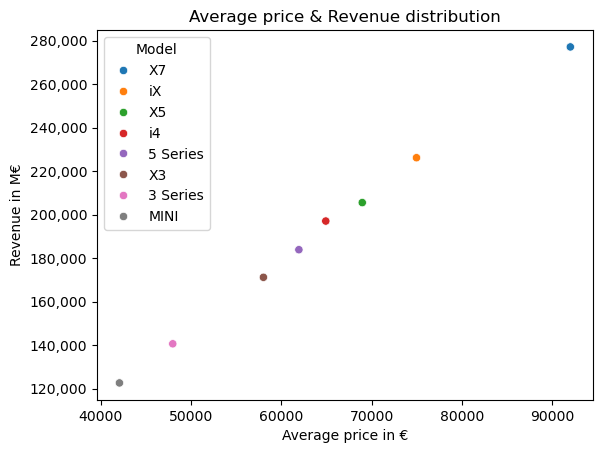

In [27]:
model_avg_price_revenue = pd.merge(model_avg_price, revenue_per_model, on='Model').round(2)

ax = sns.scatterplot(data=model_avg_price_revenue, x='Avg_Price_EUR', y='Revenue_M', hue='Model')
ax.set_title('Average price & Revenue distribution')
ax.set_ylabel('Revenue in M€')
ax.set_xlabel('Average price in €')
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.StrMethodFormatter('{x:,.0f}'));

The scatterplot confirms a **near-perfect correlation** between average price and revenue per model. In a context where unit sales are nearly equal across all models, price is the primary driver of revenue: the more expensive the model, the higher its total revenue contribution. This validates the hypothesis made in the previous analysis and demonstrates that **BMW's revenue structure is price-driven rather than volume-driven**.

### 5.f Regional price consistency

''

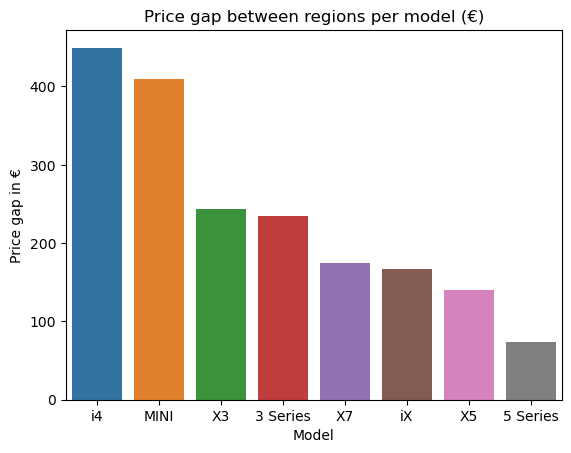

In [28]:
model_region_avg_price = df.groupby(['Model','Region'])['Avg_Price_EUR'].mean().reset_index().round(2)


# After reviewing the above dataframe, very narrow gap between model's price has been found. Thus visualising the price gap rather than prices per region.
avg_price_difference_between_region = model_region_avg_price.groupby('Model')['Avg_Price_EUR'].max() - model_region_avg_price.groupby('Model')['Avg_Price_EUR'].min()
avg_price_difference_between_region = avg_price_difference_between_region.reset_index().rename(columns={'Avg_Price_EUR':'Price_Gap_EUR'}).sort_values('Price_Gap_EUR', ascending=False)

ax = sns.barplot(data=avg_price_difference_between_region, x='Model', y='Price_Gap_EUR',hue='Model')
ax.set_title('Price gap between regions per model (€)')
ax.set_ylabel('Price gap in €')
;

BMW applies a remarkably **consistent pricing strategy** across all four regions. For every model, the price gap between the most expensive and cheapest region is below **450€**, representing less than **0.5%** of the vehicle's price in all cases.

The **i4** shows the largest regional price variation at **~450€**, while the **5 Series** is the most uniformly priced model globally at only **~75€** difference. This consistency suggests BMW maintains strict global price positioning, avoiding significant regional discounts or markups that could undermine its premium brand perception.

### 5.g Regional revenue share per model

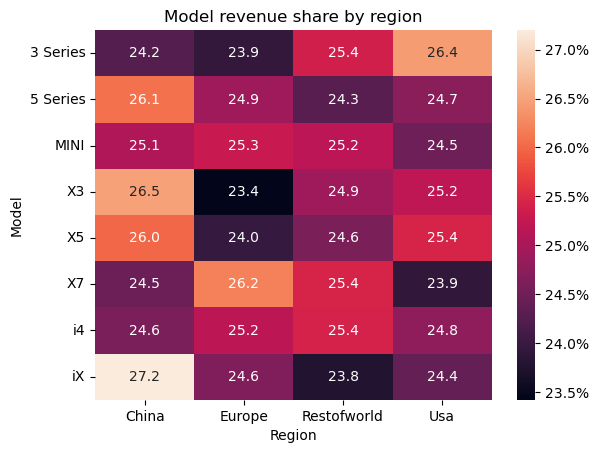

In [29]:
model_region_revenue = df.groupby(['Model','Region'])['Revenue_M'].sum().round(2).reset_index()

model_revenue_share = pd.merge(model_region_revenue, revenue_per_model, on='Model', suffixes=('_Regional','_Global')).assign(Revenue_Share= lambda df: df['Revenue_M_Regional']/df['Revenue_M_Global'] * 100).round(2)[['Model','Region','Revenue_Share']]
model_revenue_share_wide = model_revenue_share.pivot(index='Model',columns='Region',values='Revenue_Share')

ax = sns.heatmap(data=model_revenue_share_wide, annot=True, fmt='.1f')
ax.set_title('Model revenue share by region')
ax.collections[0].colorbar.ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(decimals=1));

The heatmap confirms that BMW's revenue is structurally balanced across all four regions, with every cell falling between 23.4% and 27.2%, a spread of less than 4 percentage points. No model is critically dependent on a single market, which reflects a deliberately diversified global commercial strategy.

Within this narrow range, a few meaningful patterns emerge. The **iX generates 27.2% of its revenue in China**, the highest single value in the entire table. This confirms China's role as the dominant market for BMW's flagship EV, consistent with the findings from section 3. The **X3 records its lowest share in Europe at 23.4%**, the weakest value across all models and regions. This is somewhat surprising given Europe's strong BMW presence, but aligns with the X3's declining sales trend observed in section 2.e. The **X7 derives its highest regional share from Europe at 26.2%**, consistent with section 2.f where the X7 led European sales. Conversely, the US contributes only 23.9% of X7 revenue, the lowest across all its markets, likely reflecting the competitive pressure from pickup trucks mentioned earlier. The **3 Series generates 26.4% of its revenue from the US**, the highest among all regions for this model, again consistent with the US being the only market where a sedan leads sales. Finally, the **MINI shows the most uniform distribution** (24.5% to 25.3%), suggesting it appeals equally across all markets without any regional dominance.

*Note: since section 5.f established that BMW applies near-identical pricing across all four regions (price gap below 0.5% of vehicle price), regional revenue share is mechanically proportional to regional sales volume. This heatmap therefore mirrors the sales distribution observed in section 2.f, and should be read as a confirmation rather than an independent finding.*

## 6. Macroeconomic factors

This section tests whether two macroeconomic variables in the dataset, `GDP_Growth` and `Fuel_Price_Index`, help explain BMW's sales and EV adoption patterns.

### 6.a GDP Growth vs sales

Text(0.5, 1.0, 'GDP Growth vs BMW unit sales')

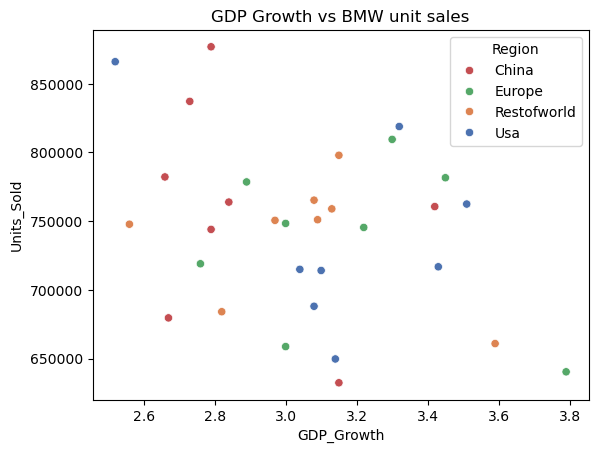

In [30]:
df.groupby(['Year','Region','Month'])['GDP_Growth'].nunique()
gdp_growth_year_region = df.groupby(['Year','Region'])['GDP_Growth'].mean().reset_index()

gdp_growth_sales_year_region = pd.merge(gdp_growth_year_region, sales_year_region, on=['Year','Region']).round(2)

ax = sns.scatterplot(data=gdp_growth_sales_year_region, x='GDP_Growth', y='Units_Sold', hue='Region', palette=country_palette)
ax.set_title('GDP Growth vs BMW unit sales')

The scatter plot reveals **no meaningful correlation** between GDP growth and BMW unit sales across any of the four regions. High GDP growth values do not correspond to higher sales volumes, and the highest sales figures actually appear at lower GDP growth levels, suggesting the opposite of what economic theory would predict.

More importantly, the distribution of GDP growth values across regions raises serious **data quality concerns**. **Europe** and **Restofworld** display the highest GDP growth values in the dataset, reaching up to **3.8%**, while **China**, the world's fastest-growing major economy over the 2018–2025 period with annual GDP growth consistently between **5% and 8%**, shows some of the lowest values. This is the inverse of real-world macroeconomic data, which strongly suggests that the `GDP_Growth` column does not accurately represent actual national GDP growth rates.

Given this inconsistency, no reliable conclusion can be drawn from this variable. It is excluded from the analysis to avoid misleading interpretations.

### 6.b Fuel Price Index vs EV adoption

Text(0.5, 1.0, 'Fuel Price Index vs EV Share')

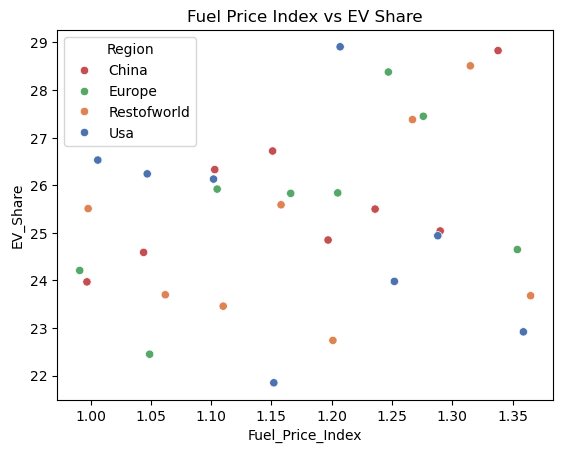

In [31]:
df.groupby(['Year','Month','Region'])['Fuel_Price_Index'].nunique()
fuel_year_region = df.groupby(['Year','Region'])['Fuel_Price_Index'].mean().reset_index()

fuel_ev_year_region = pd.merge(fuel_year_region, ev_sales_region_year_total, on=['Year','Region']).round(3)[['Year','Region','Fuel_Price_Index','EV_Share']]

ax = sns.scatterplot(data=fuel_ev_year_region, x='Fuel_Price_Index', y='EV_Share', hue='Region', palette=country_palette)
ax.set_title('Fuel Price Index vs EV Share')

The scatter plot shows **no meaningful correlation** between the fuel price index and BMW's EV share across any of the four regions. Data points are broadly dispersed with no discernible trend, indicating that higher fuel prices do not drive stronger EV adoption within BMW's sales mix.

It is worth noting that when plotting the fuel price index against absolute EV sales volumes, a positive correlation appeared. However, this was a **spurious correlation** driven by the time trend: both EV sales and fuel prices varied over the 2018–2025 period, creating a false association. Using `EV_Share`, which normalizes EV sales against total volume, removes this confounding effect and reveals the **absence of any real relationship** between the two variables.

## 7. Seasonality

This section checks for seasonal patterns in BMW sales, first at the global level, then by region, to see whether local cultural or economic cycles drive different monthly patterns.

### 7.a Global monthly sales share

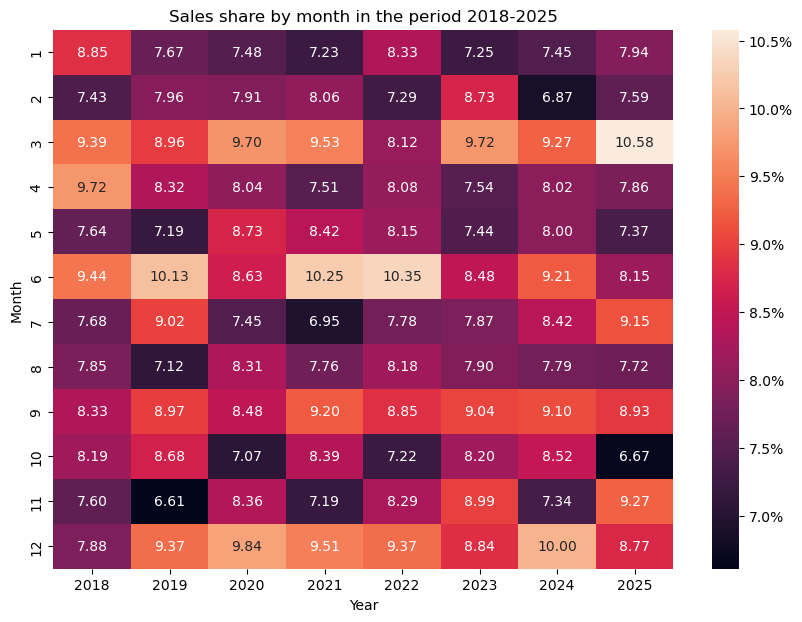

In [32]:
sales_month_year = df.groupby(['Month','Year'])['Units_Sold'].sum().reset_index()

sales_month_year_share = pd.merge(sales_month_year, sales_year, on='Year', suffixes=('_Month','_Year')).assign(Units_Sold_Share= lambda df: df['Units_Sold_Month'] / df['Units_Sold_Year'] * 100).round(2)[['Month','Year','Units_Sold_Share']]
sales_month_year_share_wide = sales_month_year_share.pivot(index='Month',columns='Year',values='Units_Sold_Share')

fig, ax = plt.subplots(figsize=(10,7))
ax = sns.heatmap(data=sales_month_year_share_wide, annot=True, fmt='.2f')
ax.set_title('Sales share by month in the period 2018-2025')
ax.collections[0].colorbar.ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(decimals=1));


BMW sales show no marked seasonality over the 2018-2025 period. The gap between the strongest and weakest month is only **1.68 percentage points**, representing a relative variation of **~22%**, a weak signal for structural seasonality.

**March** is on average the strongest month, with **9.41%** of annual sales concentrated in a single month, followed closely by **June** (**9.33%**) and **December** (**9.20%**). Four additional months exceed the 9% threshold: **April** (8.14%), **July** (8.04%) and **September** (8.86%). At the other end, the weakest months are **February** (**7.73%**) and **January** (**7.78%**), nearly **1.7 percentage points** below March.

This limited seasonality is partly explained by the breadth of BMW's lineup. With sedans, SUVs, convertibles and electric vehicles, demand spreads naturally throughout the year: convertibles peak in spring, SUVs pick up ahead of winter, and December benefits from corporate fleet renewals and year-end dealer targets.

### 7.b Monthly sales share by region

,1,2,3,4,5,6,7,8,9,10,11,12
Region,,,,,,,,,,,,
China,7.17,7.38,9.98,8.76,7.74,8.93,8.34,7.53,8.73,7.81,8.20,9.45
Europe,7.30,7.49,9.16,8.36,8.34,8.75,7.93,8.24,8.85,7.38,7.93,10.27
Restofworld,8.11,8.28,9.36,7.28,7.91,9.64,7.84,8.32,9.38,8.37,7.11,8.43
Usa,8.56,7.76,9.09,8.13,7.50,10.02,8.08,7.24,8.45,7.93,8.61,8.62


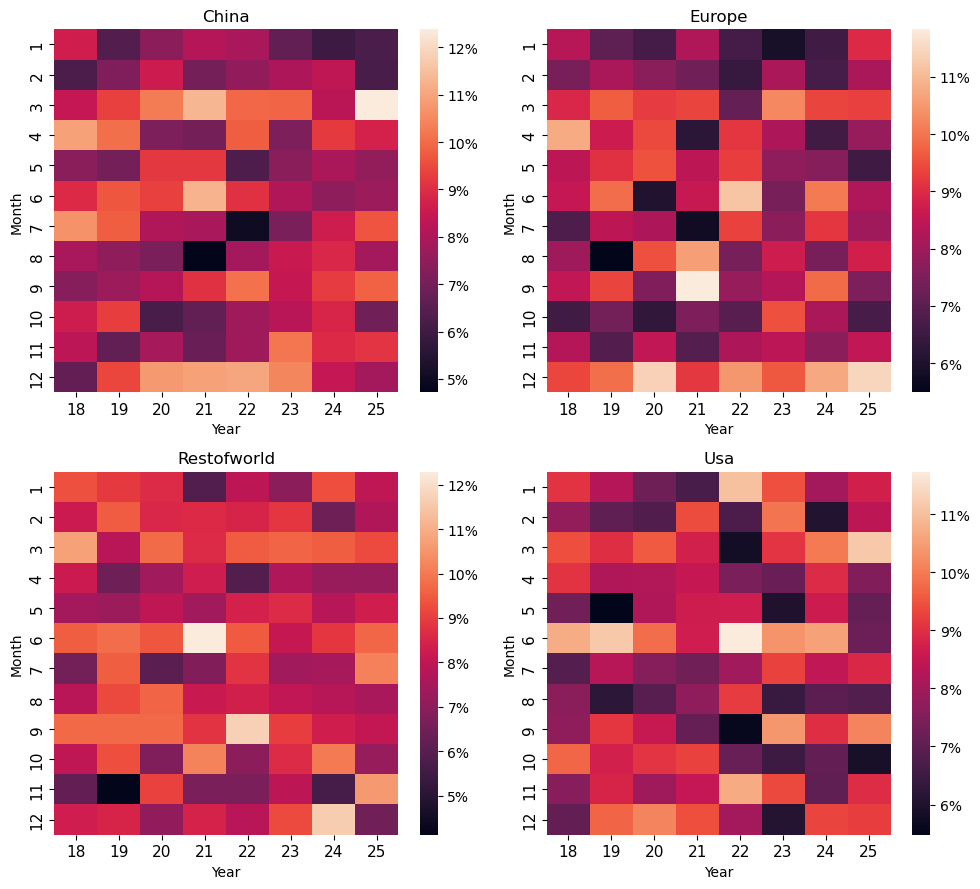

In [33]:
sales_month_year_region = df.groupby(['Month','Year','Region'])['Units_Sold'].sum().reset_index()

sales_month_year_region_share = pd.merge(sales_month_year_region, sales_year_region, on=['Region','Year'],suffixes=('_Month','_Year')).assign(Units_Sold_Share= lambda df: df['Units_Sold_Month']/df['Units_Sold_Year']*100).round(2)[['Month','Year','Region','Units_Sold_Share']]

region_avg_results = []

fig, ax = plt.subplots(2, 2, figsize=(10, 9))
ax = ax.flatten()
i = 0

for region in sales_month_year_region_share['Region'].unique():
    sns.heatmap(data=sales_month_year_region_share[sales_month_year_region_share['Region']==region].pivot(index='Month',columns='Year',values='Units_Sold_Share'), ax=ax[i])
    ax[i].set_xticklabels([str(year)[2:] for year in sales_month_year_region_share['Year'].unique()])
    ax[i].set_title(region)
    ax[i].tick_params(axis='x', rotation=0)
    ax[i].tick_params(labelsize=11)
    ax[i].collections[0].colorbar.ax.yaxis.set_major_formatter(plt.matplotlib.ticker.StrMethodFormatter('{x:,.0f}%'))
    region_avg = sales_month_year_region_share[sales_month_year_region_share['Region']==region].groupby('Month')['Units_Sold_Share'].mean().round(2)
    region_avg_results.append({'Region': region, **region_avg.to_dict()})
    i += 1

plt.tight_layout()
monthly_avg_by_region = pd.DataFrame(region_avg_results).set_index('Region')
monthly_avg_by_region

A first structural difference emerges from comparing the colorbars: **China** and **Restofworld** show a wider amplitude ranging from 5% to 12%, while **Europe** and the **Usa** display a narrower range between 6% and 11%. This suggests that the first pair of regions experience less evenly distributed sales throughout the year.

**China** records its strongest month in **March** at **9.98%** of annual sales, while its weakest is **January** at only **7.17%**. The low January figure is consistent with the Chinese New Year period, during which economic activity typically slows and consumers focus on celebrations rather than major purchases. The March peak likely reflects a spending rebound, as the red envelopes (红包) distributed during the New Year are converted into purchases in the following weeks.

**Europe** stands out with the highest single monthly peak across all four regions: **December** at **10.27%**. This is likely driven by a combination of year-end corporate fleet renewals, dealer target incentives, and the cultural dimension of Christmas as a period for high-value purchases. Conversely, **January** is the weakest month at **7.30%**, consistent with a post-holiday spending slowdown.

**Restofworld** peaks in **June** at **9.64%**, while **November** is the weakest month at **7.11%**. Given the extreme geographic and cultural diversity of this region, covering markets across Asia, Africa, Latin America and the Middle East, it is difficult to attribute clear explanations to these patterns without more granular data.

Finally, the **Usa** market also peaks in **June** at **10.02%**, potentially linked to summer car-buying season and mid-year promotions. Its weakest month is **August** at **7.24%**, which may reflect a typical summer slowdown before the back-to-school period.

## 8. Conclusion

This analysis covered seven dimensions of the BMW Group's global performance between 2018 and 2025. Several consistent patterns emerge across sections.

**Growth is real but uneven.** Total sales grew by **+27.52%** and revenue by **+28.02%**, with revenue slightly outpacing volume. This gap is not accidental: BMW's portfolio is structurally **price-driven rather than volume-driven**, and the data confirms that premiumisation has been a quiet but steady trend throughout the period. The **Usa** and **China** are the two markets most responsible for this growth, while **Restofworld** consistently lags, likely reflecting a structural mismatch between its low premium share (~6%) and BMW's positioning.

**The EV transition is happening, but unevenly.** Despite a solid average EV share of **~25%**, the overall progression over the period is only **+2.2 percentage points**, and 2025 saw a dip below average. **China** is the only region where EV momentum is clearly accelerating, while the **Usa** and **Restofworld** remain firmly anchored to thermal powertrains. The data does not allow a conclusion on whether this reflects consumer preference, infrastructure gaps, or pricing, but the divergence between regions is significant enough to suggest that a single global EV strategy may be insufficient.

**The model mix is balanced by design, but cracks are showing.** No model dominates the portfolio, with less than **4%** separating the top and bottom sellers by volume. This balance appears deliberate. However, the **X3**'s trajectory (from the highest-selling model in 2018 to the weakest growth over the period at just **+3%**) stands out as a signal worth monitoring. Conversely, the **iX** posted the strongest growth at **+45%**, suggesting that the flagship EV is gaining traction, at least in volume terms.

**Seasonality is limited but culturally grounded.** Global monthly sales share fluctuates within a narrow **1.68 percentage point** range. At the regional level, patterns become more distinct: **China's** March peak aligns with post-Chinese New Year spending, **Europe's** December spike reflects corporate fleet cycles and year-end incentives, and the **Usa** and **Restofworld** peak in June. These patterns are modest in magnitude but consistent in direction.

**Two macroeconomic variables in the dataset proved unreliable.** Both `GDP_Growth` and `Fuel_Price_Index` showed distributions inconsistent with real-world data, particularly for China, and were excluded from the core analysis. This is a methodological limitation worth noting: the absence of valid macroeconomic signals means the analysis cannot speak to how external economic conditions drove or constrained BMW's performance.

---

As this analysis draws to a close, the automotive industry is entering one of its most uncertain periods in recent memory. The ongoing closure of the **Strait of Hormuz** in early 2026 has introduced significant supply chain and energy price pressures at a time when the sector was already navigating a complex structural transition. At the same time, **EV sales in France rose by 30%** in the opening months of 2026, a signal that electrification continues to accelerate in key European markets despite the broader economic turbulence.

These external developments reinforce the relevance of the trends identified throughout this analysis and raise the stakes for the strategic choices BMW faces in the years ahead.

Sources: [2026 Strait of Hormuz campaign](https://en.wikipedia.org/wiki/2026_Strait_of_Hormuz_campaign), [Electric car sales rise sharply in 2026: grants and eligibility in France explained](https://www.connexionfrance.com/news/electric-car-sales-rise-sharply-in-2026-grants-and-eligibility-in-france-explained/791970)